In [3]:
!pip -q install "pypdf==5.9.0" pypdfium2 sentence-transformers faiss-cpu transformers accelerate bitsandbytes pandas matplotlib tqdm

In [4]:
import os, re, json, hashlib, gc, pathlib, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

OUT, CACHE, DATA = pathlib.Path("outputs"), pathlib.Path("cache"), pathlib.Path("data")
for d in (OUT, CACHE, DATA): d.mkdir(exist_ok=True)

COUNTRY = "Mexico"
PDF_NAME = "1934-7685-002.2025.issue-286-en.pdf"
PDF_PATH = DATA / PDF_NAME
PDF_URLS = [
    "https://www.imf.org/-/media/Websites/IMF/imported-full-text-pdf/external/pubs/ft/scr/2025/cr25286.ashx",
    "https://meetings.imf.org/-/media/Files/Publications/CR/2025/English/1mexea2025001-source-pdf.ashx",
    "https://www.imf.org/-/media/Files/Publications/CR/2025/English/1mexea2025001-source-pdf.ashx",
]
EXTRACT_MODEL = "Qwen/Qwen2.5-3B-Instruct"
JUDGE_MODEL = "microsoft/Phi-3.5-mini-instruct"
EMB_MODEL = "sentence-transformers/all-MiniLM-L6-v2"
CHUNK_TOKENS, OVERLAP_TOKENS = 400, 50

def save_json(obj, name):
    (OUT / name).write_text(json.dumps(obj, indent=2, ensure_ascii=False, allow_nan=False))
    return obj

def valid_pdf(path):
    if not path.exists() or path.stat().st_size < 10000: return False
    with path.open("rb") as f: return f.read(5) == b"%PDF-"

def get_pdf():
    """Use a provisioned input PDF first; then try direct IMF URLs without interaction."""
    if valid_pdf(PDF_PATH): return
    for candidate in [pathlib.Path(PDF_NAME), pathlib.Path('/content') / PDF_NAME]:
        if valid_pdf(candidate):
            import shutil
            if candidate.resolve() != PDF_PATH.resolve(): shutil.copyfile(candidate, PDF_PATH)
            return
    for url in PDF_URLS:
        try:
            r = requests.get(url, headers={"User-Agent": "Mozilla/5.0", "Accept": "application/pdf"}, timeout=45)
            r.raise_for_status()
            if not r.content.startswith(b"%PDF-"): raise ValueError("URL did not return a PDF")
            PDF_PATH.write_bytes(r.content)
            return
        except (requests.RequestException, ValueError) as exc:
            print("IMF mirror unavailable:", type(exc).__name__)
    raise FileNotFoundError(
        f"Input PDF unavailable. Place {PDF_NAME} in Colab's /content folder or data/ before running. "
        "This notebook deliberately does not stop mid-run for an interactive file upload."
    )

get_pdf()
print("PDF ready:", PDF_PATH, PDF_PATH.stat().st_size, "bytes")

PDF ready: data/1934-7685-002.2025.issue-286-en.pdf 8094257 bytes


Preprocessing - cleaning, detect section boundaries & token chunk

In [5]:
from pypdf import PdfReader
from transformers import AutoTokenizer

NUM = re.compile(r"-?\d[\d,]*\.?\d*")
NOISE = [r"©\s*International Monetary Fund\. Not for Redistribution", r"^MEXICO$",
         r"^(\d+\s+)?INTERNATIONAL MONETARY FUND(\s+\d+)?$", r"^\d{1,3}$"]

def extract_pages(path):
    """pypdf per page; if a page raises (parsing-budget limit), fall back to pypdfium2 for that page."""
    reader, pages, failed = PdfReader(path), [], []
    for i, p in enumerate(reader.pages):
        try: pages.append(p.extract_text() or "")
        except Exception as e: failed.append((i + 1, type(e).__name__)); pages.append(None)
    if failed:
        print("pypdf failed on pages (using fallback):", failed)
        import pypdfium2 as pdfium
        pdf = pdfium.PdfDocument(str(path))
        for i, t in enumerate(pages):
            if t is None: pages[i] = pdf[i].get_textpage().get_text_range()
    return pages

def clean_page(raw):
    """Drop headers/footers, re-join hard line breaks, keep table rows (>=4 numbers) on their own line."""
    lines = [l.strip() for l in raw.splitlines()]
    lines = [l for l in lines if not any(re.search(p, l, re.I) for p in NOISE)]
    out, flags = [], []
    for s in lines:
        is_row = len(NUM.findall(s)) >= 4
        if not s: out.append(""); flags.append(False); continue
        prev = out[-1] if out else ""
        merge = (prev and not is_row and not flags[-1] and not re.search(r"[.:;?!]$", prev)
                 and not re.match(r"^(\d+\.|•|[-–])\s", s))
        if merge: out[-1] = prev + " " + s
        else: out.append(s); flags.append(is_row)
    text = re.sub(r"(\w)- (\w)", r"\1\2", "\n".join(out))
    text = re.sub(r"[ \t]+", " ", text)
    return re.sub(r"\n{3,}", "\n\n", text).strip()

MAIN  = ["RECENT DEVELOPMENTS", "OUTLOOK AND RISKS", "POLICY DISCUSSIONS", "STAFF APPRAISAL"]
ANNEX = re.compile(r"^Annex ([IVX]+)\.\s+(?!Figure|Table|Box|Appendix)(.+)")

def split_sections(raw_pages, clean_pages):
    """Use actual body headings; stop Staff Appraisal before the figures/tables appendix."""
    starts = [(1, "Front Matter & Press Release")]
    for i, t in enumerate(raw_pages):
        if i < 8: continue
        lines = [line.strip() for line in t.splitlines()]
        for line in lines:
            if line in MAIN:
                starts.append((i, line.title()))
            elif re.match(r"^Figure 1a\. Mexico:", line):
                starts.append((i, "Statistical Figures & Tables"))
            else:
                m = ANNEX.match(line)
                if m: starts.append((i, f"Annex {m.group(1)}: " + re.sub(r"\s*\d$", "", m.group(2))[:55]))
    unique = []
    seen = set()
    for page, title in sorted(starts, key=lambda z: z[0]):
        if title not in seen:
            seen.add(title)
            unique.append((page, title))
    return {
        title: "\n".join(clean_pages[page:(unique[j+1][0] if j+1 < len(unique) else len(clean_pages))])
        for j, (page, title) in enumerate(unique)
    }
qtok = AutoTokenizer.from_pretrained(EXTRACT_MODEL)
tok_len = lambda s: len(qtok.encode(s, add_special_tokens=False))

def chunk_text(text, size=CHUNK_TOKENS, overlap=OVERLAP_TOKENS):
    """Sentence-aware windows of ~size tokens; last ~overlap tokens carried into the next chunk."""
    sents = [s for s in re.split(r"(?<=[.!?])\s+|\n", text) if s.strip()]
    chunks, cur, cur_len = [], [], 0
    for s in sents:
        l = tok_len(s)
        if cur and cur_len + l > size:
            chunks.append(" ".join(x for x, _ in cur))
            keep, kl = [], 0
            for x, xl in reversed(cur):
                if kl + xl > overlap: break
                keep.insert(0, (x, xl)); kl += xl
            cur, cur_len = keep, kl
        if l > size:
            tokens = qtok.encode(s, add_special_tokens=False)
            for start in range(0, len(tokens), size - overlap):
                part = qtok.decode(tokens[start:start + size], skip_special_tokens=True)
                if cur: chunks.append(" ".join(x for x, _ in cur)); cur, cur_len = [], 0
                chunks.append(part)
            continue
        cur.append((s, l)); cur_len += l
    if cur: chunks.append(" ".join(x for x, _ in cur))
    return chunks

raw_pages   = extract_pages(PDF_PATH)
clean_pages = [clean_page(t) for t in raw_pages]
sections    = split_sections(raw_pages, clean_pages)
chunks = []
for n, t in sections.items():
    for c in chunk_text(t):
        chunks.append({"id": len(chunks), "section": n, "text": c, "tokens": tok_len(c)})
sec_chunks  = {n: [c["text"] for c in chunks if c["section"] == n] for n in sections}
total_words = sum(len(t.split()) for t in sections.values())
save_json(chunks, "chunks.json")
print(len(raw_pages), "pages |", len(sections), "sections |", len(chunks), "chunks")
for n, t in sections.items(): print(f"{n[:50]:50s} {len(t.split()):6d} words")

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

116 pages | 19 sections | 211 chunks
Front Matter & Press Release                         2284 words
Recent Developments                                  1379 words
Outlook And Risks                                    1349 words
Policy Discussions                                   4939 words
Staff Appraisal                                      1451 words
Statistical Figures & Tables                         5579 words
Annex I: External Sector Assessment                  1027 words
Annex II: Risk Assessment Matrix                      832 words
Annex III: Key FSAP Recommendations                  2067 words
Annex IV: Debt Sustainability Analysis               4632 words
Annex V: Data Issues                                 1144 words
Annex VI: Mexico’s Trade Landscape and the USMCA R   3027 words
Annex VII: Going Back Home: Implications of U.S. I   1430 words
Annex VIII: Revenue Administration Efforts: Scope    1146 words
Annex IX: Barriers to Competition and Fintech Pene   1744 words
Ann

FAISS RAG with document-content-addressed embeddings cache

In [6]:
import faiss
from sentence_transformers import SentenceTransformer

emb = SentenceTransformer(EMB_MODEL); emb.max_seq_length = 512
EMB_FILE = CACHE / "chunk_embeddings.npy"
EMB_META = CACHE / "chunk_embeddings.meta.json"
emb_key = hashlib.sha256(json.dumps({"model": EMB_MODEL, "chunks": [c["text"] for c in chunks]},
                                    ensure_ascii=False).encode()).hexdigest()
use_cache = False
if EMB_FILE.exists() and EMB_META.exists():
    try:
        meta = json.loads(EMB_META.read_text())
        use_cache = meta.get("sha256") == emb_key
    except (OSError, ValueError): pass
if use_cache:
    E = np.load(EMB_FILE).astype("float32")
else:
    E = emb.encode([c["text"] for c in chunks], batch_size=32, normalize_embeddings=True,
                   show_progress_bar=True).astype("float32")
    np.save(EMB_FILE, E)
    EMB_META.write_text(json.dumps({"sha256": emb_key, "model": EMB_MODEL, "n": len(chunks)}))
index = faiss.IndexFlatL2(E.shape[1]); index.add(E)
faiss.write_index(index, str(OUT / "mexico_faiss.index"))

def retrieve(query, k=4, section=None):
    """Top-k actual dense-vector neighbors; optionally restrict to one report section."""
    q = emb.encode([query], normalize_embeddings=True).astype("float32")
    D, I = index.search(q, len(chunks) if section else min(k, len(chunks)))
    res = []
    for d, i in zip(D[0], I[0]):
        if i < 0: continue
        if section and chunks[i]["section"] != section: continue
        res.append({**chunks[i], "dist": float(d)})
        if len(res) == k: break
    return res

ctx_of = lambda hits: "\n---\n".join(h["text"] for h in hits)
print(retrieve("policy rate path and inflation target", k=2)[0]["text"][:300])

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/7 [00:00<?, ?it/s]

Structural Current Spending Rule (In percent of GDP) Share of Programmable Spending (RHS) Budget 1/ Outturn Sources: SHCP, and IMF staff calculations. 1/ Budget refers to the maximum limit calculated in the budget in t-1 according to the rule of not exceeding potential growth. B. Guiding Inflation D


Two local LLMs & cache generation

In [7]:
import torch
from transformers import AutoModelForCausalLM, BitsAndBytesConfig

MODEL = TOK = None
CUR_NAME = EXTRACT_MODEL

def load_llm(name, quant=False):
    tok = AutoTokenizer.from_pretrained(name)
    if quant: kw = dict(quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                                                               bnb_4bit_compute_dtype=torch.float16))
    else:     kw = dict(dtype=torch.float16)
    try: model = AutoModelForCausalLM.from_pretrained(name, device_map="auto", **kw)
    except TypeError:
        kw["torch_dtype"] = kw.pop("dtype")
        model = AutoModelForCausalLM.from_pretrained(name, device_map="auto", **kw)
    return model, tok

def free_llm():
    global MODEL, TOK
    MODEL = TOK = None; gc.collect(); torch.cuda.empty_cache()

def chat(system, user, max_new_tokens=300):
    """Cache-first generation. The model is loaded lazily, only if this prompt is not already cached."""
    global MODEL, TOK
    key = hashlib.sha256(f"{CUR_NAME}|{system}|{user}|{max_new_tokens}".encode()).hexdigest()[:24]
    f = CACHE / f"llm_{key}.txt"
    if f.exists(): return f.read_text()
    if MODEL is None:
        print("Loading", CUR_NAME)
        MODEL, TOK = load_llm(CUR_NAME, quant=(CUR_NAME == JUDGE_MODEL))   # judge in 4-bit, extractor in fp16
    msgs = [{"role": "system", "content": system}, {"role": "user", "content": user}]
    inp = TOK.apply_chat_template(msgs, add_generation_prompt=True, return_tensors="pt", return_dict=True).to(MODEL.device)
    with torch.no_grad():
        out = MODEL.generate(**inp, max_new_tokens=max_new_tokens, do_sample=False)
    text = TOK.decode(out[0][inp["input_ids"].shape[1]:], skip_special_tokens=True).strip()
    f.write_text(text); return text

def parse_json(s):
    m = re.search(r"\{.*\}", s, re.S)
    try: return json.loads(m.group(0))
    except Exception: return None

print("Ready. GPU memory in use:", round(torch.cuda.memory_allocated()/1e9, 1), "GB")

Ready. GPU memory in use: 0.1 GB


In [8]:
from tqdm.auto import tqdm

SYS_ANALYST = ("You are a careful financial-stability analyst. Use ONLY the supplied IMF report text. "
               "Never add figures or facts that are not in the text. If something is not stated, omit it.")
SUM_FOCUS = "key findings, risks, vulnerabilities and policy recommendations"
RULES = ("Do not attach a forecast or number to a year unless the text states it explicitly. "
         "Write complete sentences.")

def trim_to_sentence(s):
    """If generation stopped mid-sentence, cut back to the last full sentence."""
    s = s.strip()
    if s.endswith((".", "!", "?")): return s
    cut = max(s.rfind(". "), s.rfind("! "), s.rfind("? "))
    return s[:cut + 1] if cut > 0 else s + "."

def summarise_section(name, k=6):
    """Retrieval-selected summarisation: the k most relevant chunks, kept in document order."""
    hits = sorted(retrieve(f"{SUM_FOCUS} {name}", k=k, section=name), key=lambda h: h["id"])
    body = "\n".join(h["text"] for h in hits)
    s = chat(SYS_ANALYST, f"Summarise the section '{name}' in at most 80 words of plain prose (no bullets, no preamble). {RULES}\n\nTEXT:\n{body}", 220)
    if len(s.split()) >= 100:
        s = chat(SYS_ANALYST, f"Shorten this to under 80 words, keeping the key findings:\n\n{s}", 220)
    return trim_to_sentence(s)

section_summaries = {n: summarise_section(n) for n in tqdm(sec_chunks) if n != "Statistical Figures & Tables"}
save_json({n: {"summary": s, "words": len(s.split())} for n, s in section_summaries.items()}, "section_summaries.json")

focus = [n for n in section_summaries if n.startswith(("Outlook", "Staff Appraisal", "Policy", "Annex II:", "Annex III:", "Annex IV:"))]
exec_summary = trim_to_sentence(chat(SYS_ANALYST,
    "Write 6-8 bullet points (each starting with '- ') summarising the primary financial-stability findings and risk "
    "assessments of this IMF report on Mexico. Use only the section summaries below and copy numbers exactly. "
    f"{RULES}\n\n" + "\n".join(f"[{n}] {section_summaries[n]}" for n in focus), 400))
save_json({"executive_summary": exec_summary}, "executive_summary.json")
print(exec_summary)
print("\nSummaries >= 100 words:", [n for n, s in section_summaries.items() if len(s.split()) >= 100] or "none")
for n, s in section_summaries.items(): print(f"\n[{n}] ({len(s.split())} words)\n{s}")

  0%|          | 0/19 [00:00<?, ?it/s]

Loading Qwen/Qwen2.5-3B-Instruct


model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

- Growth is forecasted to slow to 1% this year due to domestic policy and U.S. trade policies, but is expected to rebound to 2% in 2026.
- Fiscal risks arise from insufficient consolidation, potentially increasing financing costs and deterring investment.
- Authorities acknowledge easing inflation due to weaker economic activity and falling service prices but note elevated inflation expectations.
- The Staff Appraisal suggests that while growth is expected to pick up slightly in 2026, further fiscal consolidation is necessary to keep public debt manageable.
- High-likelihood/high-impact risks identified include escalating trade measures, prolonged uncertainty, commodity price volatility, financial market volatility and correction, geopolitical tensions, cyber threats, climate change, new trade agreements, and rising social discontent.
- Key FSAP Recommendations include enhancing regulatory autonomy, improving supervision structure, aligning regulations, strengthening oversight of payme

Seven financial-stability themes

In [8]:
THEMES = {
 "Inflation & Prices": r"inflation|disinflation|consumer prices|\bCPI\b|price pressures|price stability",
 "Interest Rates & Credit": r"interest rate|policy rate|monetary policy|\bcredit\b|lending|Banxico|rate cut|tightening|easing",
 "Housing & Real Estate": r"housing|mortgage|real estate|property|residential",
 "Banking Capital & Liquidity": r"capital adequacy|\bcapital\b|liquidity|\bTier 1\b|\bCET1\b|buffer|solvency|stress test|\bbanks?\b",
 "Sovereign Debt": r"public debt|sovereign|debt sustainability|fiscal deficit|\bdebt\b|borrowing|bond",
 "Labor Market Dynamics": r"\blabou?r\b|unemployment|\bwages?\b|employment|informal|workers",
 "Systemic Financial Risk": r"systemic|financial stability|contagion|spillover|vulnerabilit|\bFSAP\b|financial sector risk|stress",
}
theme_wide = pd.DataFrame({t: {n: len(re.findall(rx, txt, re.I)) for n, txt in sections.items()}
                           for t, rx in THEMES.items()})
theme_wide.index.name = "section"
theme_totals  = theme_wide.sum()
theme_density = (theme_totals / total_words * 1000).round(2)
save_json({"counts": theme_totals.to_dict(), "per_1000_words": theme_density.to_dict(),
           "by_section": theme_wide.to_dict(orient="index")}, "themes.json")
print(theme_density.sort_values(ascending=False))

Strengths and vulnerabilities

In [9]:
STR_Q = ["strengths and resilience of the economy", "strong financial sector capital buffers", "credibility of the policy framework"]
VUL_Q = ["downside risks to the outlook", "fiscal pressures and public debt", "financial sector vulnerabilities and credit risks"]
def gather(qs, k=3):
    seen, out = set(), []
    for q in qs:
        for h in retrieve(q, k=k):
            if h["id"] not in seen: seen.add(h["id"]); out.append(h)
    return out

qual_ctx = ctx_of(gather(STR_Q)) + "\n===\n" + ctx_of(gather(VUL_Q))
qual_raw = chat(SYS_ANALYST,
    'From the excerpts, list the national macroeconomic strengths/growth drivers and the systemic vulnerabilities/challenges. '
    'Max 6 short items each. Return ONLY JSON: {"strengths": [...], "vulnerabilities": [...]}\n\nEXCERPTS:\n' + qual_ctx, 500)
qual = parse_json(qual_raw) or {"strengths": [], "vulnerabilities": []}
qual = {"strengths": qual.get("strengths", [])[:7], "vulnerabilities": qual.get("vulnerabilities", [])[:7]}
save_json(qual, "qualitative_insights.json"); print(json.dumps(qual, indent=2))

{
  "strengths": [
    "Moderate risk of debt distress mitigated by a robust fiscal framework",
    "Sound banking system with high levels of capital and liquidity",
    "Low leverage in corporate and household sectors",
    "Resilient financial system with ample margins to absorb shocks",
    "Flexible exchange rate serving as a shock absorber",
    "Increasing access to financial services"
  ],
  "vulnerabilities": [
    "Systemic risks remain tilted to the upside, particularly concerning inflation expectations",
    "Limited diversification of export sector exposure",
    "Potential vulnerabilities in border regions due to indirect exposures",
    "Cybersecurity challenges",
    "Weaknesses in the fiscal framework, including flexibility in setting fiscal targets and escape clauses",
    "Uncertainty in the medium-term outlook for the current account balance"
  ]
}


IMF source table extraction and time-series preparation

In [10]:
T1 = r"Table 1\. Mexico: Selected Economic, Financial, and Social"
T5 = r"Table 5\. Mexico: Financial Soundness"

def row_values(page_key, label_rx, n):
    """Find the table page, then the first row matching the label; return its last n numbers (or NaNs)."""
    for t in raw_pages:
        if re.search(page_key, t):
            for l in t.splitlines():
                if re.search(label_rx, l.strip(), re.I):
                    nums = [float(x.replace(",", "")) for x in NUM.findall(l)]
                    if len(nums) >= n: return nums[-n:]
    print("WARNING: row not found ->", label_rx)
    return [np.nan] * n

Y1, Y5 = list(range(2021, 2031)), list(range(2019, 2026))
trend_wide = pd.DataFrame({
  "Real GDP growth (%)":             row_values(T1, r"^GDP\b", 10),
  "Consumer prices, end-period (%)": row_values(T1, r"^Consumer prices \(end-of-period\)", 10),
  "Core consumer prices (%)":        row_values(T1, r"^Core consumer prices", 10),
  "Monetary policy rate (%)":        row_values(T1, r"^Monetary policy rate", 10),
  "Private credit growth (%)":       row_values(T1, r"^Financial system credit", 10),
  "Unemployment rate (%)":           row_values(T1, r"^National unemployment rate", 10)}, index=Y1)
fsi_wide = pd.DataFrame({
  "NPL ratio (%)":            row_values(T5, r"^Nonperforming loans to total gross", 7),
  "Tier 1 capital ratio (%)": row_values(T5, r"^Regulatory Tier 1 capital", 7)}, index=Y5)
save_json({"table1_2021_2030": trend_wide.to_dict(), "fsi_2019_2025": fsi_wide.to_dict()}, "temporal_trends.json")
print(trend_wide, "\n\n", fsi_wide)
# Physical PDF page references used to distinguish table evidence from LLM statements.
def find_table_page(pattern):
    hits = [i + 1 for i, text in enumerate(raw_pages) if re.search(pattern, text)]
    return hits[0] if hits else None
TABLE_PAGES = {"Table 1": find_table_page(T1), "Table 5": find_table_page(T5)}
print("Source PDF pages:", TABLE_PAGES)

      Real GDP growth (%)  Consumer prices, end-period (%)  \
2021                  6.0                              7.4   
2022                  3.7                              7.8   
2023                  3.4                              4.7   
2024                  1.4                              4.2   
2025                  1.0                              3.7   
2026                  1.5                              3.0   
2027                  2.0                              3.0   
2028                  2.1                              3.0   
2029                  2.1                              3.0   
2030                  2.1                              3.0   

      Core consumer prices (%)  Monetary policy rate (%)  \
2021                       5.9                      5.50   
2022                       8.3                     10.50   
2023                       5.1                     11.25   
2024                       3.7                     10.00   
2025             

LLM indicators table verification

In [11]:
FALLBACK = -1.0
SPEC = {
 "gdp_growth_forecast_pct":      ("Projected real GDP growth for 2026 (percent)", "real GDP growth projection 2026", trend_wide["Real GDP growth (%)"], 2026, "Table 1"),
 "headline_inflation_rate_pct":  ("Headline consumer price inflation, end of period 2025 (percent)", "consumer prices inflation end of period 2025", trend_wide["Consumer prices, end-period (%)"], 2025, "Table 1"),
 "central_bank_policy_rate_pct": ("Banxico monetary policy rate in 2025 (percent, NOT basis-point rate changes)", "monetary policy rate Banxico 2025", trend_wide["Monetary policy rate (%)"], 2025, "Table 1"),
 "non_performing_loan_ratio":    ("NPL to total gross loans, June 2025 (percent)", "nonperforming loans to total gross loans", fsi_wide["NPL ratio (%)"], 2025, "Table 5"),
 "unemployment_rate_pct":        ("National unemployment rate, 2025 (percent)", "national unemployment rate 2025", trend_wide["Unemployment rate (%)"], 2025, "Table 1"),
 "tier_1_capital_ratio":         ("Regulatory Tier 1 capital to risk-weighted assets, June 2025 (percent)", "regulatory Tier 1 capital to risk-weighted assets", fsi_wide["Tier 1 capital ratio (%)"], 2025, "Table 5"),
}
SYS_EXTRACT = (
 'Extract the requested indicator only when its exact period and percentage unit are explicit. '
 'A change of 375 basis points is NOT a 375 percent policy rate. '
 'Return only valid JSON: {"value": <number or null>, "evidence": "<source quote>"}. '
 'Do not guess, convert other measures, or infer dates.'
)

def table_evidence(table):
    """Return physical PDF table text, not a synthetic or model-generated context."""
    p = TABLE_PAGES.get(table)
    return raw_pages[p - 1] if p else ""

def parse_float(v):
    if isinstance(v, bool): return None
    try: return float(v) if v is not None else None
    except (TypeError, ValueError): return None

llm_raw, final, prov = {}, {"country_name": COUNTRY}, {}
for field, (desc, query, ref_series, year, table) in SPEC.items():
    hits = retrieve(query, k=4)
    ctx = ctx_of(hits)
    table_text = table_evidence(table)
    excerpt = (table_text[:10000] + "\n--- Retrieved discussion ---\n" + ctx[:3000])
    out = parse_json(chat(SYS_EXTRACT, f"Quantity: {desc}\n\nSOURCE TEXT:\n{excerpt}", 160)) or {}
    raw_value = parse_float(out.get("value"))
    reference = ref_series.loc[year] if year in ref_series.index else np.nan
    reference = None if pd.isna(reference) else float(reference)
    agrees = (raw_value is not None and reference is not None and abs(raw_value - reference) <= 0.051)
    if reference is not None:
        value, method = reference, "verified_table_parser"
    else:
        value, method = FALLBACK, "missing_table_value"
    final[field] = float(value)
    llm_raw[field] = out
    prov[field] = {"requested_period": "June 2025" if table == "Table 5" else str(year),
                   "llm_value": raw_value, "reference_value": reference,
                   "agrees_with_reference": bool(agrees), "source_used": method,
                   "source_table": table, "pdf_page": TABLE_PAGES.get(table),
                   "evidence": out.get("evidence"),
                   "retrieved_sections": [h["section"] for h in hits]}
save_json(final, "core_indicators.json")
save_json(prov, "indicator_provenance.json")
save_json(llm_raw, "llm_raw_indicators.json")
extraction_accuracy = float(np.mean([p["agrees_with_reference"] for p in prov.values()]))
llm_only = {"country_name": COUNTRY}
for field, p in prov.items():
    llm_only[field] = p["llm_value"] if p["agrees_with_reference"] else FALLBACK
save_json(llm_only, "llm_only_indicators.json")
print("Verified table-based indicators:\n", json.dumps(final, indent=2))
print("LLM-only agreement with independently parsed tables:", f"{extraction_accuracy:.0%}")
print(pd.DataFrame(prov).T[["llm_value", "reference_value", "agrees_with_reference", "source_used", "pdf_page"]])

Verified table-based indicators:
 {
  "country_name": "Mexico",
  "gdp_growth_forecast_pct": 1.5,
  "headline_inflation_rate_pct": 3.7,
  "central_bank_policy_rate_pct": 7.5,
  "non_performing_loan_ratio": 2.1,
  "unemployment_rate_pct": 2.9,
  "tier_1_capital_ratio": 17.9
}
LLM-only agreement with independently parsed tables: 83%
                             llm_value reference_value agrees_with_reference  \
gdp_growth_forecast_pct            1.5             1.5                  True   
headline_inflation_rate_pct        3.7             3.7                  True   
central_bank_policy_rate_pct       7.5             7.5                  True   
non_performing_loan_ratio          2.1             2.1                  True   
unemployment_rate_pct              3.0             2.9                 False   
tier_1_capital_ratio              17.9            17.9                  True   

                                        source_used pdf_page  
gdp_growth_forecast_pct       verified_tabl

RAG and no-RAG retrieval comparison

In [12]:
QUESTIONS = ["What does the IMF recommend about bank capital buffers and financial sector supervision?",
             "What is the inflation target and when is inflation expected to return to it?",
             "What are the main risks to the economic outlook?"]
SYS_RAG   = "Answer ONLY from the excerpts. If the answer is not in them, say 'Not stated in the retrieved text.' Be concise (max 70 words)."
SYS_NORAG = "Answer concisely (max 70 words) about the IMF 2025 Article IV report on Mexico."
rag_demo = []
for q in QUESTIONS:
    hits = retrieve(q, k=4)
    rag_demo.append({"question": q, "context": ctx_of(hits), "sources": [h["section"] for h in hits],
                     "answer_rag": chat(SYS_RAG, f"EXCERPTS:\n{ctx_of(hits)}\n\nQUESTION: {q}", 160),
                     "answer_no_rag": chat(SYS_NORAG, q, 160)})
save_json(rag_demo, "rag_demo.json")
for r in rag_demo: print("Q:", r["question"], "\nSources:", r["sources"], "\nRAG:", r["answer_rag"], "\nNO-RAG:", r["answer_no_rag"], "\n")

Q: What does the IMF recommend about bank capital buffers and financial sector supervision? 
Sources: ['Annex XIII: Transnational Aspects of Corruption: Updates', 'Policy Discussions', 'Annex III: Key FSAP Recommendations', 'Annex IV: Debt Sustainability Analysis'] 
RAG: IMF recommends authorities see no immediate need for countercyclical buffers or new borrower-based limits, and emphasize interagency coordination and risk-based supervision. 
NO-RAG: IMF recommends strengthening bank capital buffers and enhancing financial sector supervision in Mexico. 

Q: What is the inflation target and when is inflation expected to return to it? 
Sources: ['Policy Discussions', 'Statistical Figures & Tables', 'Annex XIII: Transnational Aspects of Corruption: Updates', 'Recent Developments'] 
RAG: The inflation target is 3%, and inflation is expected to return to it by the third quarter of 2026. 
NO-RAG: IMF's 2025 Article IV report for Mexico aims to stabilize inflation at 3% by 2024, with a medium

Independent judge audit

In [13]:
free_llm(); CUR_NAME = JUDGE_MODEL
print("GPU memory in use:", round(torch.cuda.memory_allocated()/1e9, 1), "GB")

SYS_JUDGE = (
    "You are an independent strict IMF report evaluator. Compare every claim with the SOURCE. "
    "Do not assume your own score is proof of truth. Rate consistency, completeness, factual_alignment "
    "as integers from 1 to 5; if evidence is insufficient state that in issues. "
    'Return one JSON object only: {"consistency": 1, "completeness": 1, "factual_alignment": 1, "issues": "reason"}. '
    "No markdown or prose outside JSON."
)
MAX_EVIDENCE_CHARS = 6000

def judge_text(label, candidate, evidence):
    prompt = f"SOURCE:\n{evidence[:MAX_EVIDENCE_CHARS]}\n\nCANDIDATE ({label}):\n{candidate}"
    answer = chat(SYS_JUDGE, prompt, 220)
    data = parse_json(answer)
    def valid(d):
        return isinstance(d, dict) and all(
            isinstance(d.get(k), (int, float)) and not isinstance(d.get(k), bool) and 1 <= d[k] <= 5
            for k in ("consistency", "completeness", "factual_alignment")
        )
    if not valid(data):
        retry_sys = SYS_JUDGE + " IMPORTANT: output exactly four JSON keys, integers 1-5 for scores."
        data = parse_json(chat(retry_sys, prompt, 180))
    if not valid(data):
        return {"consistency": None, "completeness": None, "factual_alignment": None,
                "issues": "Invalid judge JSON after retry; excluded from means", "status": "parse_failed"}
    return {"consistency": int(data["consistency"]), "completeness": int(data["completeness"]),
            "factual_alignment": int(data["factual_alignment"]),
            "issues": str(data.get("issues", "")), "status": "scored"}

rows = []
for name, summary in tqdm(section_summaries.items()):
    rows.append({"item": f"summary: {name}",
                 **judge_text("section summary", summary, ctx_of(retrieve(summary, k=3, section=name)))})
rows.append({"item": "executive summary",
             **judge_text("executive summary", exec_summary, ctx_of(retrieve(exec_summary, k=4)))})
for record in rag_demo:
    for kind, key in [("RAG", "answer_rag"), ("no-RAG", "answer_no_rag")]:
        rows.append({"item": f"{kind} answer: {record['question'][:40]}",
                     **judge_text("answer", record[key], record["context"])})
judge_df = pd.DataFrame(rows)
for col in ("consistency", "completeness", "factual_alignment"):
    judge_df[col] = pd.to_numeric(judge_df[col], errors="coerce")
SYS_IJ = ('Audit the claimed value against the exact requested variable, unit and date in the SOURCE TABLE. '
          'Return ONLY JSON: {"verdict": "supported" | "unsupported" | "not_found", "reason": "short reason"}.')
indicator_audit = {}
for field, (desc, _, _, _, table) in SPEC.items():
    prompt = f"Requested measure: {desc}\nClaimed value: {final[field]} percent\nSOURCE TABLE:\n{table_evidence(table)[:12000]}"
    result = parse_json(chat(SYS_IJ, prompt, 120)) or {}
    verdict = result.get("verdict")
    if verdict not in {"supported", "unsupported", "not_found"}: verdict = "unparseable"
    indicator_audit[field] = {"judge_verdict": verdict, "reason": result.get("reason", ""),
                              "value": final[field], "source": prov[field]["source_used"],
                              "source_pdf_page": prov[field]["pdf_page"]}

score_cols = ["consistency", "completeness", "factual_alignment"]
valid_rows = int(judge_df[score_cols].notna().all(axis=1).sum())
missing_rows = len(judge_df) - valid_rows
save_json({"scores": judge_df.replace({np.nan: None}).to_dict(orient="records"),
           "indicator_audit": indicator_audit,
           "valid_judge_rows": valid_rows, "unparseable_judge_rows": missing_rows,
           "mean_scores_valid_only": judge_df[score_cols].mean().round(2).replace({np.nan: None}).to_dict()},
          "judge_audit.json")
print(judge_df[["item", *score_cols, "status"]].to_string(index=False))
print("Unparseable judge rows:", missing_rows, "out of", len(judge_df))
print("Indicator audits:", indicator_audit)
free_llm()

GPU memory in use: 0.1 GB


  0%|          | 0/18 [00:00<?, ?it/s]

Loading microsoft/Phi-3.5-mini-instruct


config.json:   0%|          | 0.00/3.45k [00:00<?, ?B/s]

[transformers] This model config has set a `rope_parameters['original_max_position_embeddings']` field, to be used together with `max_position_embeddings` to determine a scaling factor. Please set the `factor` field of `rope_parameters`with this ratio instead -- we recommend the use of this field over `original_max_position_embeddings`, as it is compatible with most model architectures.


tokenizer_config.json:   0%|          | 0.00/3.98k [00:00<?, ?B/s]

... (7 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/195 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/195 [00:00<?, ?B/s]

                                                                  item  consistency  completeness  factual_alignment status
                                 summary: Front Matter & Press Release            5             5                  5 scored
                                          summary: Recent Developments            5             5                  5 scored
                                            summary: Outlook And Risks            5             5                  5 scored
                                           summary: Policy Discussions            5             5                  5 scored
                                              summary: Staff Appraisal            5             5                  5 scored
                          summary: Annex I: External Sector Assessment            5             5                  5 scored
                             summary: Annex II: Risk Assessment Matrix            5             5                  5 scored
        

Dashboard

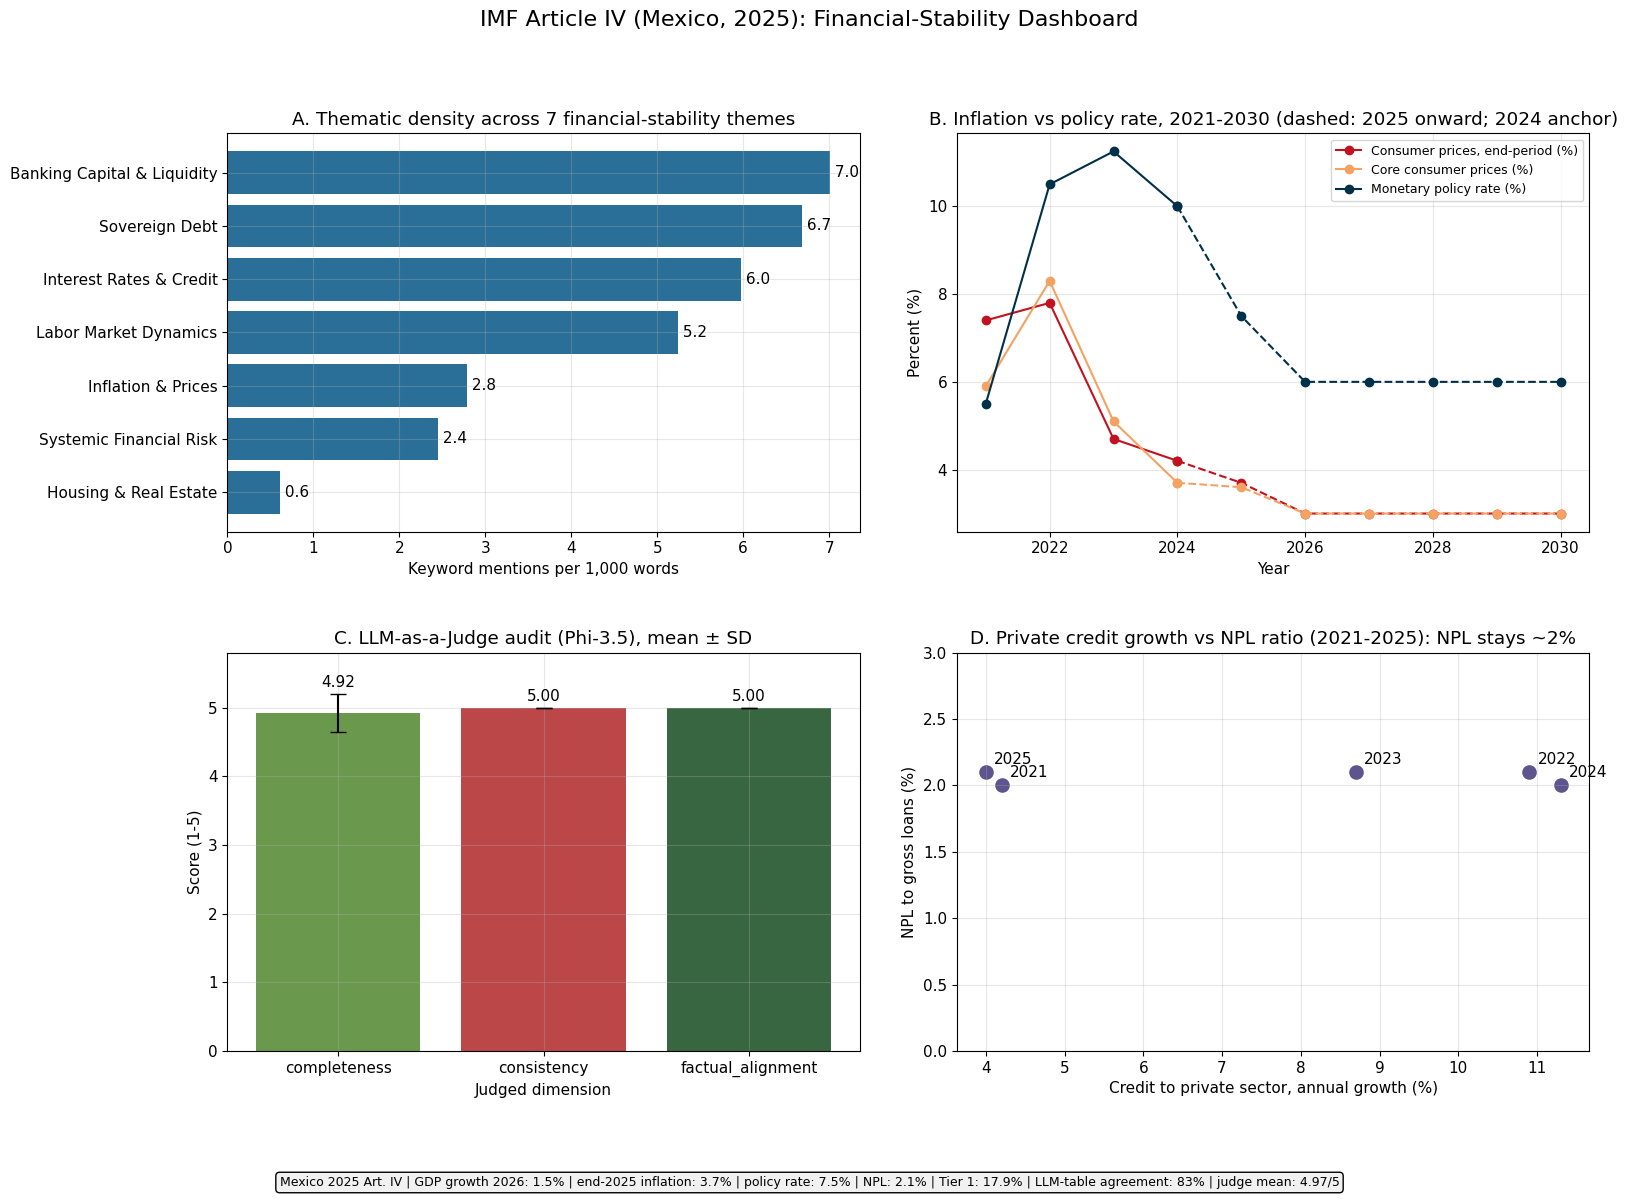

In [16]:
def pick(df, key):
    m = [c for c in df.columns if key.lower() in c.lower()]
    if not m: raise KeyError(f"No column containing '{key}'. Available: {list(df.columns)}.")
    return m[0]

# Safely define variables if they are missing from the current kernel session
if 'theme_wide' not in globals():
    THEMES = {
        "Inflation & Prices": r"inflation|disinflation|consumer prices|\bCPI\b|price pressures|price stability",
        "Interest Rates & Credit": r"interest rate|policy rate|monetary policy|\bcredit\b|lending|Banxico|rate cut|tightening|easing",
        "Housing & Real Estate": r"housing|mortgage|real estate|property|residential",
        "Banking Capital & Liquidity": r"capital adequacy|\bcapital\b|liquidity|\bTier 1\b|\bCET1\b|buffer|solvency|stress test|\bbanks?\b",
        "Sovereign Debt": r"public debt|sovereign|debt sustainability|fiscal deficit|\bdebt\b|borrowing|bond",
        "Labor Market Dynamics": r"\blabou?r\b|unemployment|\bwages?\b|employment|informal|workers",
        "Systemic Financial Risk": r"systemic|financial stability|contagion|spillover|vulnerabilit|\bFSAP\b|financial sector risk|stress",
    }
    theme_wide = pd.DataFrame({t: {n: len(re.findall(rx, txt, re.I)) for n, txt in sections.items()}
                               for t, rx in THEMES.items()})
    theme_wide.index.name = "section"

CREDIT_COL = pick(trend_wide, "credit"); NPL_COL = pick(fsi_wide, "NPL")
CPI_COL = pick(trend_wide, "Consumer prices, end"); CORE_COL = pick(trend_wide, "Core consumer"); RATE_COL = pick(trend_wide, "policy rate")

theme_long = pd.melt(theme_wide.reset_index(), id_vars="section", var_name="theme", value_name="mentions")
theme_dens = (theme_long.groupby("theme")["mentions"].sum() / total_words * 1000).sort_values()
tw = trend_wide.copy(); tw.index.name = "year"
trend_long = pd.melt(tw.reset_index(), id_vars="year", var_name="indicator", value_name="percent")
judge_long = pd.melt(judge_df, id_vars="item", value_vars=["consistency", "completeness", "factual_alignment"],
                     var_name="dimension", value_name="score").dropna()
save_json({"theme_long": theme_long.to_dict("records"), "trend_long": trend_long.to_dict("records")}, "tidy_long_tables.json")

plt.rcParams.update({"font.size": 11, "axes.grid": True, "grid.alpha": 0.3})
fig, ax = plt.subplots(2, 2, figsize=(17, 12))

a = ax[0, 0]; a.barh(theme_dens.index, theme_dens.values, color="#2a6f97")
a.set_title("A. Thematic density across 7 financial-stability themes"); a.set_xlabel("Keyword mentions per 1,000 words")
for i, v in enumerate(theme_dens.values): a.text(v, i, f" {v:.1f}", va="center")

b = ax[0, 1]
for ind, col in [(CPI_COL, "#c1121f"), (CORE_COL, "#f4a261"), (RATE_COL, "#003049")]:
    dd = trend_long[trend_long.indicator == ind]
    b.plot(dd[dd.year <= 2024].year, dd[dd.year <= 2024].percent, color=col, marker="o", label=ind)
    b.plot(dd[dd.year >= 2024].year, dd[dd.year >= 2024].percent, color=col, marker="o", ls="--")
b.set_title("B. Inflation vs policy rate, 2021-2030 (dashed: 2025 onward; 2024 anchor)")
b.set_xlabel("Year"); b.set_ylabel("Percent (%)"); b.legend(fontsize=9)

c = ax[1, 0]; g = judge_long.groupby("dimension")["score"].agg(["mean", "std"]).fillna(0)
c.bar(g.index, g["mean"], yerr=g["std"], capsize=6, color=["#6a994e", "#bc4749", "#386641"][:len(g)])
c.set_ylim(0, 5.8); c.set_title("C. LLM-as-a-Judge audit (Phi-3.5), mean ± SD")
c.set_ylabel("Score (1-5)"); c.set_xlabel("Judged dimension")
for i, (m, sd) in enumerate(zip(g["mean"], g["std"])): c.text(i, m + sd + 0.1, f"{m:.2f}", ha="center")

dax = ax[1, 1]; yrs = list(range(2021, 2026))
x = trend_wide.loc[yrs, CREDIT_COL]; y_ = fsi_wide.loc[yrs, NPL_COL]
dax.scatter(x, y_, s=90, color="#5e548e")
for yr, xi, yi in zip(yrs, x, y_): dax.annotate(str(yr), (xi, yi), textcoords="offset points", xytext=(6, 6))
dax.set_ylim(0, 3); dax.set_title("D. Private credit growth vs NPL ratio (2021-2025): NPL stays ~2%")
dax.set_xlabel("Credit to private sector, annual growth (%)"); dax.set_ylabel("NPL to gross loans (%)")

summary = (f"{COUNTRY} 2025 Art. IV | GDP growth 2026: {final['gdp_growth_forecast_pct']}% | end-2025 inflation: {final['headline_inflation_rate_pct']}% | "
           f"policy rate: {final['central_bank_policy_rate_pct']}% | NPL: {final['non_performing_loan_ratio']}% | Tier 1: {final['tier_1_capital_ratio']}% | "
           f"LLM-table agreement: {extraction_accuracy:.0%} | judge mean: {judge_long.score.mean():.2f}/5")
fig.suptitle("IMF Article IV (Mexico, 2025): Financial-Stability Dashboard", fontsize=16, y=0.99)
fig.text(0.5, 0.01, summary, ha="center", fontsize=9, wrap=True, bbox=dict(boxstyle="round", fc="#f1f1f1"))
fig.tight_layout(rect=[0.02, 0.07, 0.98, 0.95], h_pad=3.5, w_pad=2.8)
fig.savefig(OUT / "dashboard.png", dpi=300, bbox_inches="tight"); plt.show()